# 1. CSV2Julia Rules, Parameter Naming & Modes

In Tutorials 1 and 2, you built small 3–4 species models by editing CSV files and re-running `csv2model-multiscale.py` every single time you changed a number.

That works fine for a 3-protein Toy Model — **but real published models in the Mitchell Lab have over 100 molecular species, 400 reactions, and 250 parameters!** When you want to test ten drugs, compare five cancer cell lines, or feed in time-varying biological signals, you need to know:

1. **The exact rules of [`CSV2Julia`](https://github.com/SiFTW/TLR9Modelling/tree/main/csv2Julia)** (`csv2model-multiscale.py`), especially how to name and number parameters so your tables always translate cleanly into Julia ODEs.
2. **The three ways to run `CSV2Julia`** (`inline`, `scan`, and `param`) — and why **`param` mode** is the secret weapon behind our published models.
3. **How to change parameters at run-time** in Julia *without* ever editing a CSV or regenerating the ODE file!

:::{tip} Start your live Julia kernel
Click **Activate Live Editable Julia Cells** near the top of the page (if you haven't already), then press **Shift + Enter** to run each cell!
:::

---

## The General Rules of `CSV2Julia`

Every `CSV2Julia` model starts from **three CSV spreadsheets** (plain comma-separated tables that you can edit in Excel, Google Sheets, or right here in Julia):

| File | Required Columns | What It Describes |
|---|---|---|
| `reactions.csv` | `Substrate`, `Products`, `Kinetic Law`, `Modifiers`, `Parameters` | Every arrow in your biological diagram (one row per reaction) |
| `parameters.csv` | `Parameter`, `Value` *(optional extra columns like `distribute` are allowed!)* | The numerical value — or time-dependent curve — of every parameter |
| `ratelaws.csv` | `Rate Law Name`, `Rate Law Definition` | Reusable mathematical recipes with placeholders for species and parameters |

```{figure} ../images/csv2julia-rules.svg
:alt: Diagram showing how CSV2Julia matches placeholders in ratelaws.csv with species in reactions.csv and parameter values in parameters.csv using the Golden Underscore Rule
:width: 100%

How `CSV2Julia` connects your three CSV tables. Species slots (`[S1]`, `[Mod1]`) are matched **by position**; parameter slots (`{k1}`, `{k2}`) are matched **by the prefix before the first underscore `_`**!
```

Here are the **five general rules** that guarantee `CSV2Julia` works every time:

1. **Row 1 is always a header row.** `CSV2Julia` automatically skips the very first row of each CSV file, so never put a real reaction or parameter on line 1.
2. **Commas separate columns; spaces separate multiple items inside a cell.**
   - Need two substrates binding together? Write `NFkB IkB` (separated by a **space**, never a comma!).
   - Need two parameters in one reaction? Write `k1_IkBexp k2_IkBexp` (separated by a **space**!).
   - Leave a cell empty when a reaction has no substrates (like synthesis `-> A`), no products (like degradation `C ->`), or no modifiers.
3. **Rate law names must match exactly.** Whatever text you put in the `Kinetic Law` column of `reactions.csv` must match a row in `ratelaws.csv` **character-for-character** (including capitalisation and spaces).
4. **Species placeholders are 1-indexed and matched by position:**
   - Substrates: `[S1]`, `[S2]`, `[S3]`, ... *(case-insensitive: `[s1]` also works)*
   - Products: `[P1]`, `[P2]`, ...
   - Modifiers: `[Mod1]`, `[Mod2]`, ... *(case-insensitive: `[mod1]` also works)*
   - Count starting from **1** (not 0). If `Substrate` is `NFkB IkB`, then `[S1]` is `NFkB` and `[S2]` is `IkB`. If you swap their order in `reactions.csv`, `[S1]` and `[S2]` swap too!
   - `CSV2Julia` automatically discovers every species name, saves them to `variableNames.jl` (`syms = [...]`) in order of first appearance, subtracts the rate law (`-`) from each substrate, adds it (`+`) to each product, gives pure modifiers `dy[i] = 0`, and wraps every species in `maximum([y[i], 0])` so concentrations can never accidentally drop below zero.
5. **The Golden Rule of Parameter Naming & Numbering (`prefix_uniqueLabel`):**
   This is the #1 rule to understand so your models never silently break!

---

## Deep Dive: How to Name & Number Parameters

Look closely at how `CSV2Julia` substitutes parameters into a rate law:

1. In **`ratelaws.csv`**, every parameter slot is wrapped in curly braces, like `{k1}`, `{k2}`, `{kon}`, `{vmax}`, `{Km}`, `{Kd1}`, `{ikk1}`, or `{nik}`.
2. In **`reactions.csv`** and **`parameters.csv`**, every parameter name MUST have the format:

   ```text
   prefix_uniqueDescription
   ```

   For example: `k1_IkBexp`, `k2_IkBexp`, `kon_NFkBIkB`, `Kd1_p100Synth`, `ikk1_ikkactivity`.
3. When `CSV2Julia` reads a parameter name from `reactions.csv`, it **splits the name at the very first underscore `_`** and takes only the piece **before** `_` (the **prefix**). It then looks for `{prefix}` inside the rate law and substitutes that parameter in!

:::{warning} Three Classic Parameter-Naming Pitfalls (and How to Avoid Them!)
1. **Never put an underscore inside `{placeholder}` in `ratelaws.csv`!**
   - **Wrong:** `{k_on}` with parameter `k_on_bind` → splitting `k_on_bind` at the first `_` gives `k`, which **does not match** `{k_on}`! `CSV2Julia` strips the curly braces and leaves a bare undefined variable `k_on` inside the ODE function, crashing Julia with `UndefVarError: k_on not defined`!
   - **Right:** `{kon}` with parameter `kon_bind` (or `{k1}` with `k1_bind`).
2. **Number distinct parameters in the same rate law (`{k1}`, `{k2}`, `{Kd1}`, `{Kd2}`...)**
   - **Wrong:** Putting `{k}` twice, or listing `k1_max k1_half` for a reaction with `{k1}` and `{k2}` — both start with `k1_`, so `CSV2Julia` tries to jam **both** into `{k1}` and leaves bare `k2` unreplaced!
   - **Right:** Give every parameter slot in a rate law its **own unique prefix** (`{k1}` and `{k2}`, or `{vmax}` and `{Km}`, or `{Kd1}`, `{Kd2}`, `{Kd3}`, `{Kd4}` as in the published NF-κB model!).
3. **Match spelling & capitalisation character-for-character between `reactions.csv` and `parameters.csv`.**
   - `k1_Aexp` and `k1_aexp` are treated as two completely different names.
   - *(Bonus tip: unlike `[S1]`/`[Mod1]`, because parameters match by prefix before `_`, writing `k2_IkBexp k1_IkBexp` still finds `{k1}` and `{k2}` correctly — though listing them in order is much easier for humans to read!)*
:::

### Quick Check: Test Your `CSV2Julia` Rules Intuition

Try answering these three quick questions before revealing the answers:

1. A rate law is written as `[S1] * {k_deg}` and `reactions.csv` lists parameter `k_deg_IkB`. Why will `CSV2Julia` fail to substitute `{k_deg}`?
   ````{admonition} Hint
   :class: dropdown tip
   What does `CSV2Julia` get when it splits `k_deg_IkB` at the **first** underscore `_`?
   ````
   ````{admonition} Reveal Answer
   :class: dropdown note
   Splitting `k_deg_IkB` at the first `_` gives **`k`**, NOT **`k_deg`**! Because `k != k_deg`, `{k_deg}` is never replaced (leaving a bare undefined variable `k_deg` in the ODE file). Fix it by removing the underscore inside the curly braces: write `[S1] * {kdeg}` with `kdeg_IkB` (or `[S1] * {k1}` with `k1_IkBdeg`).
   ````

2. A reaction has `Modifiers` = `RelAnp50n RelBnp52n`. Which species does `[Mod2]` stand for?
   ````{admonition} Hint
   :class: dropdown tip
   Modifier placeholders are 1-indexed and matched by position from left to right.
   ````
   ````{admonition} Reveal Answer
   :class: dropdown note
   **`RelBnp52n`**! `[Mod1]` is the 1st modifier (`RelAnp50n`) and `[Mod2]` is the 2nd modifier (`RelBnp52n`).
   ````

3. In `parameters.csv`, why can we have `k1_AtoB` and `k1_BtoC` in the **same** model even though both start with `k1_`?
   ````{admonition} Hint
   :class: dropdown tip
   Are `k1_AtoB` and `k1_BtoC` used in the *same* reaction row, or in *different* reaction rows?
   ````
   ````{admonition} Reveal Answer
   :class: dropdown note
   They are in **different reactions**! Each reaction only sees the parameters listed on its own row in `reactions.csv`. Sharing the `k1_` prefix across *different* reactions is how hundreds of reactions reuse the same simple `[S1] * {k1}` rate law while keeping distinct numerical values in `parameters.csv`!
   ````

---

## Hands-on Exercise 1: Catch & Fix a Broken Parameter Name!

Let's load our Julia packages and run a tiny deliberately broken model so you can see *with your own eyes* what happens when the underscore rule is broken — and then fix it!

In [1]:
using DifferentialEquations
using Plots
using CSV
using DataFrames

gr()

# Deliberately broken CSVs: spot the two parameter naming/numbering bugs!
write("ratelaws_broken.csv", """
Rate Law Name    , Rate Law Definition
Bad Induction    , {k_max} * ([Mod1] / ({k2} + [Mod1]))
""")

write("reactions_broken.csv", """
Substrate , Products , Kinetic Law   , Modifiers , Parameters
          , IkB      , Bad Induction , NFkB      , k_max_IkB k1_IkBhalf
""")

write("parameters_broken.csv", """
Parameter  , Value
k_max_IkB  , 20
k1_IkBhalf , 5
""")

run(`python3 csv2model-multiscale.py reactions_broken.csv parameters_broken.csv ratelaws_broken.csv brokenModel.jl inline`)

println("\n--- Look at the generated brokenModel.jl! ---")
println(read("brokenModel.jl", String))

inline
Running CSV2JuliaDiffEq with parameters hard-coded into the CSV file, if this is not correct, re-run with the 5th argument set to 'scan' or 'param'
Opening ratelaws_broken.csv as rate law file
Opening parameters_broken.csv as parameters file
Opening reactions_broken.csv as reactions file



--- Look at the generated brokenModel.jl! ---
#######################################################
# Generated programmatically by CSV2JuliaDiffEq.      #
# http://github.com/SiFTW/CSV2JuliaDiffEq             #
#######################################################
# generated from:
#    reactions file: reactions_broken.csv
#    parameters file file: parameters_broken.csv
#    rate law file: ratelaws_broken.csv
#
# Statistics:
#    Equations:2
#    Parameters:2
#######################################################



function brokenModel(dy,y,p,t)
	IkB=maximum([y[1],0])
	NFkB=maximum([y[2],0])
	#IkB
	dy[1]= + k_max * (NFkB / (k2 + NFkB))
	#NFkB
	dy[2]=0
end



Look at line `dy[1]= + k_max * (NFkB / (k2 + NFkB))` in the output above!
`CSV2Julia` finished without crashing, **but neither `20` nor `5` was substituted** — instead, bare undefined variable names **`k_max`** and **`k2`** were left inside the equation because:
1. `{k_max}` has an underscore inside the braces (splitting `k_max_IkB` at the first `_` gave `k`, not `k_max`).
2. `k1_IkBhalf` starts with `k1`, which doesn't match `{k2}`!

If you try to solve `brokenModel`, Julia immediately throws **`UndefVarError: k_max not defined`**!

**Your task:** Edit the cell below to fix both parameter naming/numbering bugs so the generated `fixedModel.jl` substitutes `20` and `5` cleanly and plots a working 30-minute simulation!

In [2]:
# Exercise 1: Fix the broken rate law, reaction, and parameter names below!
write("ratelaws_fix.csv", """
Rate Law Name    , Rate Law Definition
Good Induction   , {k_max} * ([Mod1] / ({k2} + [Mod1]))
""")

write("reactions_fix.csv", """
Substrate , Products , Kinetic Law    , Modifiers , Parameters
          , IkB      , Good Induction , NFkB      , k_max_IkB k1_IkBhalf
""")

write("parameters_fix.csv", """
Parameter  , Value
k_max_IkB  , 20
k1_IkBhalf , 5
""")

run(`python3 csv2model-multiscale.py reactions_fix.csv parameters_fix.csv ratelaws_fix.csv fixedModel.jl inline`)
println(read("fixedModel.jl", String))

include("fixedModel.jl")
include("variableNames.jl")

try
    sol_fix = solve(ODEProblem(ODEFunction(fixedModel), [0.0, 10.0], (0.0, 30.0)))
    plot(sol_fix, label=permutedims(syms), xlabel="Time (min)", ylabel="Concentration (nM)", title="Fixed Model!", lw=2.5)
catch err
    println("⚠ Simulation failed with: ", err)
    println("👉 Check the generated ODE above for unreplaced placeholder names, fix the CSVs using the Golden Underscore Rule, and re-run!")
end

inline
Running CSV2JuliaDiffEq with parameters hard-coded into the CSV file, if this is not correct, re-run with the 5th argument set to 'scan' or 'param'
Opening ratelaws_fix.csv as rate law file
Opening parameters_fix.csv as parameters file
Opening reactions_fix.csv as reactions file
#######################################################
# Generated programmatically by CSV2JuliaDiffEq.      #
# http://github.com/SiFTW/CSV2JuliaDiffEq             #
#######################################################
# generated from:
#    reactions file: reactions_fix.csv
#    parameters file file: parameters_fix.csv
#    rate law file: ratelaws_fix.csv
#
# Statistics:
#    Equations:2
#    Parameters:2
#######################################################



function fixedModel(dy,y,p,t)
	IkB=maximum([y[1],0])
	NFkB=maximum([y[2],0])
	#IkB
	dy[1]= + k_max * (NFkB / (k2 + NFkB))
	#NFkB
	dy[2]=0
end



⚠ Simulation failed with: UndefVarError

(:

k_max)
👉 Check the generated ODE above for unreplaced placeholder names, fix the CSVs using the Golden Underscore Rule, and re-run!


```{admonition} Hint
:class: dropdown tip

- In `ratelaws_fix.csv`, change `{k_max}` to `{kmax}` (or `{k1}`) — **no underscore inside `{...}`!**
- Make sure the two parameter names in `reactions_fix.csv` and `parameters_fix.csv` start with prefixes that match the two `{...}` placeholders (for example `kmax_IkB` and `k2_IkBhalf`, or `k1_IkB` and `k2_IkBhalf`).
```

````{admonition} Reveal Solution
:class: dropdown note

```julia
write("ratelaws_fix.csv", """
Rate Law Name    , Rate Law Definition
Good Induction   , {k1} * ([Mod1] / ({k2} + [Mod1]))
""")

write("reactions_fix.csv", """
Substrate , Products , Kinetic Law    , Modifiers , Parameters
          , IkB      , Good Induction , NFkB      , k1_IkB k2_IkBhalf
""")

write("parameters_fix.csv", """
Parameter  , Value
k1_IkB     , 20
k2_IkBhalf , 5
""")

run(`python3 csv2model-multiscale.py reactions_fix.csv parameters_fix.csv ratelaws_fix.csv fixedModel.jl inline`)
generated = read("fixedModel.jl", String)
println(generated)

include("fixedModel.jl")
include("variableNames.jl")
sol_fix = solve(ODEProblem(ODEFunction(fixedModel), [0.0, 10.0], (0.0, 30.0)))
plot(sol_fix, label=permutedims(syms), xlabel="Time (min)", ylabel="Concentration (nM)", title="Fixed Model!", lw=2.5)
```
````

---

## The Three Modes of `CSV2Julia`: `inline`, `scan`, and `param`

When you call `csv2model-multiscale.py`, you pass **4 required arguments** plus an **optional 5th argument** that chooses the execution mode:

```bash
python3 csv2model-multiscale.py  reactions.csv  parameters.csv  ratelaws.csv  outputModel.jl  [inline | scan | param]
```

```{figure} ../images/csv2julia-modes.svg
:alt: Visual comparison of CSV2Julia inline, scan, and param modes showing the generated ODE code and how parameters are modified
:width: 100%

The three ways to generate Julia code with `CSV2Julia`. In Tutorials 1 and 2 we omitted the 5th argument, which defaults to `inline`. Modern published models use **`param`**.
```

Let's run `csv2model-multiscale.py` on our familiar 3-species **Toy Model** ($\emptyset \to A \to B \to C \to \emptyset$) in **all three modes** and inspect the generated Julia files side by side!

In [3]:
# 1. Generate Toy Model in INLINE mode (default)
run(`python3 csv2model-multiscale.py reactions.csv parameters.csv ratelaws.csv toy_inline.jl inline`)
println("================ 1. INLINE MODE (toy_inline.jl) ================")
println(read("toy_inline.jl", String))

inline
Running CSV2JuliaDiffEq with parameters hard-coded into the CSV file, if this is not correct, re-run with the 5th argument set to 'scan' or 'param'
Opening ratelaws.csv as rate law file
Opening parameters.csv as parameters file
Opening reactions.csv as reactions file
================ 1. INLINE MODE (toy_inline.jl) ================
#######################################################
# Generated programmatically by CSV2JuliaDiffEq.      #
# http://github.com/SiFTW/CSV2JuliaDiffEq             #
#######################################################
# generated from:
#    reactions file: reactions.csv
#    parameters file file: parameters.csv
#    rate law file: ratelaws.csv
#
# Statistics:
#    Equations:3
#    Parameters:4
#######################################################



function toy_inline(dy,y,p,t)
	A=maximum([y[1],0])
	B=maximum([y[2],0])
	C=maximum([y[3],0])
	#A
	dy[1]= + 1 - A * 2
	#B
	dy[2]= + A * 2 - B * 3
	#C
	dy[3]= + B * 3 - C * 4
end



In [4]:
# 2. Generate Toy Model in SCAN mode
run(`python3 csv2model-multiscale.py reactions.csv parameters.csv ratelaws.csv toy_scan.jl scan`)
println("================ 2. SCAN MODE (toy_scan.jl) ================")
println(read("toy_scan.jl", String))
println("-------- Accompanying scanIncludes.jl (scan mode) --------")
println(read("scanIncludes.jl", String))

scan
Running CSV2JuliaDiffEq with parameters left as a function call to paramFun(n), for all params. We will also create a paramFun.jl file that should be included and defines all parameters. If this is incorrect, please re-run with 5th argument set to 'inline' or 'param'
Opening ratelaws.csv as rate law file
Opening parameters.csv as parameters file
Opening reactions.csv as reactions file
================ 2. SCAN MODE (toy_scan.jl) ================
#######################################################
# Generated programmatically by CSV2JuliaDiffEq.      #
# http://github.com/SiFTW/CSV2JuliaDiffEq             #
#######################################################
# generated from:
#    reactions file: reactions.csv
#    parameters file file: parameters.csv
#    rate law file: ratelaws.csv
#
# Statistics:
#    Equations:3
#    Parameters:4
#######################################################



function toy_scan(dy,y,p,t)
	A=maximum([y[1],0])
	B=maximum([y[2],0])
	C=maximum([y[

In [5]:
# 3. Generate Toy Model in PARAM mode (Recommended!)
run(`python3 csv2model-multiscale.py reactions.csv parameters.csv ratelaws.csv toy_param.jl param`)
println("================ 3. PARAM MODE (toy_param.jl) ================")
println(read("toy_param.jl", String))
println("-------- Accompanying scanIncludes.jl (param mode) --------")
println(read("scanIncludes.jl", String))

param
Running CSV2JuliaDiffEq with parameters dynamically determined by a variable, re-run with the 5th argument set to 'scan' or 'inline'
Opening ratelaws.csv as rate law file
Opening parameters.csv as parameters file
Opening reactions.csv as reactions file
================ 3. PARAM MODE (toy_param.jl) ================
#######################################################
# Generated programmatically by CSV2JuliaDiffEq.      #
# http://github.com/SiFTW/CSV2JuliaDiffEq             #
#######################################################
# generated from:
#    reactions file: reactions.csv
#    parameters file file: parameters.csv
#    rate law file: ratelaws.csv
#
# Statistics:
#    Equations:3
#    Parameters:4
#######################################################



function toy_param(dy,y,p,t)
	A=maximum([y[1],0])
	B=maximum([y[2],0])
	C=maximum([y[3],0])
	#A
	dy[1]= + p[1] - A * p[2]
	#B
	dy[2]= + A * p[2] - B * p[3]
	#C
	dy[3]= + B * p[3] - C * p[4]
end

-------- Accompanying

Look closely at the three outputs above — the difference is crystal clear!

| Mode | What appears in the ODE file? | Extra file created? | How do you change a parameter at run-time? | Best for |
|---|---|---|---|---|
| **`inline`** *(default)* | Hard-coded numbers (`1`, `2`, `3`, `4`) | Only `variableNames.jl` | You **can't** — you must edit `parameters.csv` and re-run `CSV2Julia` | Learning & reading equations |
| **`scan`** | `paramFun("k1_Aexp", modify)` | `variableNames.jl` + `scanIncludes.jl` (defines `parameterList` & `modify` Dicts) | Set fold-change multiplier: `modify["k1_Aexp"] = 5.0` | Quick legacy parameter scans |
| **`param`** ★ | Array lookups `p[1]`, `p[2]` (or `p[i](t)` for curves!) | `variableNames.jl` + `scanIncludes.jl` (defines `paramVals` & `parameterNameList` arrays) | Copy `paramVals`, find the index by name, modify it, and pass it into `ODEProblem(..., myParams)`! | **All modern models**, parameter sweeps, sensitivity analysis, cell populations, and swappable time-dependent inputs! |

---

## Changing Parameters at Run-Time (Toy Model)

Let's try **both** `scan` mode and `param` mode live on the Toy Model — changing `k1_Aexp` (the synthesis rate of protein **A**) to **3× faster** *without* touching any CSV file or re-running `csv2model-multiscale.py`!

### Way A: Using `scan` mode (`modify["..."]`)

In `scan` mode, `scanIncludes.jl` creates a Julia **dictionary** called `modify` where every parameter starts at `1.0` (meaning 1× baseline). Setting `modify["k1_Aexp"] = 3.0` multiplies `k1_Aexp` by 3!

*(Important catch: because `modify` is a single shared global dictionary, you have to remember to reset `modify["k1_Aexp"] = 1.0` afterwards so later simulations don't inherit the change!)*

scan
Running CSV2JuliaDiffEq with parameters left as a function call to paramFun(n), for all params. We will also create a paramFun.jl file that should be included and defines all parameters. If this is incorrect, please re-run with 5th argument set to 'inline' or 'param'
Opening ratelaws.csv as rate law file
Opening parameters.csv as parameters file
Opening reactions.csv as reactions file


parameters can now be modified by name.
example to modify k_binding 1.5 fold higher:
modify["k_binding"]=1.5


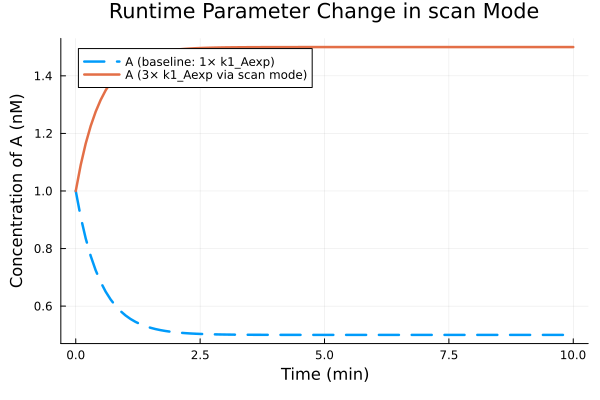

In [6]:
# Regenerate scan mode's scanIncludes.jl (since param mode overwrote it above)
run(`python3 csv2model-multiscale.py reactions.csv parameters.csv ratelaws.csv toy_scan.jl scan`)
include("toy_scan.jl")
include("variableNames.jl")
include("scanIncludes.jl")

y0 = [1.0, 0.0, 0.0]
tspan = (0.0, 10.0)

# Baseline (all modify values are 1.0)
sol_base_scan = solve(ODEProblem(ODEFunction(toy_scan), y0, tspan), saveat=0.1)

# Change k1_Aexp to 3x higher AT RUN-TIME (no CSV editing, no Python re-run!)
modify["k1_Aexp"] = 3.0
sol_3x_scan = solve(ODEProblem(ODEFunction(toy_scan), y0, tspan), saveat=0.1)

# Reset modify back to 1.0 so we leave things tidy!
modify["k1_Aexp"] = 1.0

plot(sol_base_scan.t, sol_base_scan[1, :], label="A (baseline: 1× k1_Aexp)", lw=2.5, ls=:dash)
plot!(sol_3x_scan.t,  sol_3x_scan[1, :],   label="A (3× k1_Aexp via scan mode)", lw=2.5,
      xlabel="Time (min)", ylabel="Concentration of A (nM)",
      title="Runtime Parameter Change in scan Mode")

### Way B: Using `param` mode (`paramVals` + `parameterNameList`) — The Modern Lab Way!

Now look how much cleaner **`param` mode** is! Instead of mutating a global dictionary, `scanIncludes.jl` gives us two aligned lists (arrays):

- **`paramVals`**: the list of baseline values `[1, 2, 3, 4]`
- **`parameterNameList`**: the list of parameter names `["k1_Aexp", "k1_AtoB", "k1_BtoC", "k1_Cdeg"]`

To change a parameter safely at run-time, we follow a **3-line recipe** you will use in almost every Mitchell Lab notebook:

1. **Make a fresh copy** of the baseline parameters so you never accidentally overwrite the originals:
   ```julia
   myParams = copy(paramVals)
   ```
   *(Think of `copy(paramVals)` as making a photocopy of a recipe before scribbling notes on it!)*
2. **Look up the parameter's position (index)** by name:
   ```julia
   idx = findfirst(x -> x == "k1_Aexp", parameterNameList)
   ```
   *(Plain English: "Search `parameterNameList` and return the first slot number whose text equals `"k1_Aexp"`".)*
3. **Modify that slot** (either multiply for a fold-change, `myParams[idx] *= 3.0`, or set an exact new number, `myParams[idx] = 5.0`) and pass `myParams` as the **4th argument** to `ODEProblem(ODEFunction(toy_param), y0, tspan, myParams)`!

Let's run it right now!

param
Running CSV2JuliaDiffEq with parameters dynamically determined by a variable, re-run with the 5th argument set to 'scan' or 'inline'
Opening ratelaws.csv as rate law file
Opening parameters.csv as parameters file
Opening reactions.csv as reactions file
parameters can now be searched in parameterNameList by name.
example to modify k_binding 1.5 fold higher:
indexOfParam=findfirst(x->"k_binding"==x,parameterNameList)
paramVals[indexOfParam]=paramVals[indexOfParam]*1.5


k1_Aexp lives at index 1 (baseline value = 1)
Original paramVals is still: 

[1, 2, 3, 4]


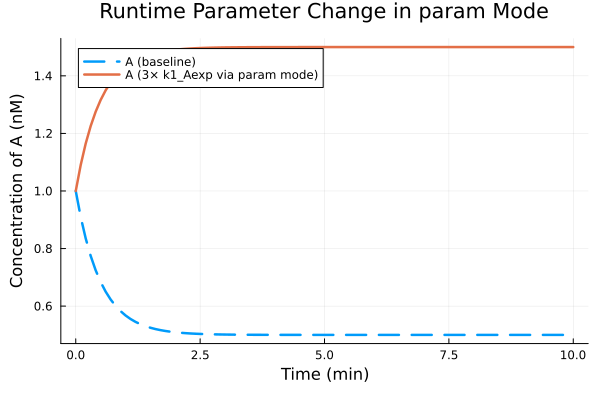

In [7]:
# Generate in PARAM mode
run(`python3 csv2model-multiscale.py reactions.csv parameters.csv ratelaws.csv toy_param.jl param`)
include("toy_param.jl")
include("variableNames.jl")
include("scanIncludes.jl")

# Notice that paramVals is passed as the 4th argument to ODEProblem!
p_base = copy(paramVals)
sol_base = solve(ODEProblem(ODEFunction(toy_param), y0, tspan, p_base), saveat=0.1)

# Make a fresh copy and scale k1_Aexp by 3x
p_3x = copy(paramVals)
idx_Aexp = findfirst(x -> x == "k1_Aexp", parameterNameList)
println("k1_Aexp lives at index ", idx_Aexp, " (baseline value = ", p_3x[idx_Aexp], ")")

p_3x[idx_Aexp] = p_3x[idx_Aexp] * 3.0
sol_3x = solve(ODEProblem(ODEFunction(toy_param), y0, tspan, p_3x), saveat=0.1)

# Original paramVals is completely untouched!
println("Original paramVals is still: ", paramVals)

plot(sol_base.t, sol_base[1, :], label="A (baseline)", lw=2.5, ls=:dash)
plot!(sol_3x.t,  sol_3x[1, :],   label="A (3× k1_Aexp via param mode)", lw=2.5,
      xlabel="Time (min)", ylabel="Concentration of A (nM)",
      title="Runtime Parameter Change in param Mode")

---

## Hands-on Exercise 2: Run a Runtime Parameter Sweep in `param` Mode!

Suppose you have a candidate drug that changes the **degradation rate of protein C** (`k1_Cdeg`) in our Toy Model.

**Your task:** Using `toy_param`, `paramVals`, and `parameterNameList` (already loaded above — **do NOT re-run `csv2model-multiscale.py`!**):
1. Find the index of **`k1_Cdeg`** in `parameterNameList`.
2. Simulate **three conditions** at run-time by scaling `k1_Cdeg` by **`0.25×`** (slower degradation), **`1.0×`** (baseline), and **`3.0×`** (faster degradation).
3. Plot the concentration of species **`C`** (index `3` in `syms`) for all three conditions on the same graph!

*(Bonus: notice how effortlessly a `for` loop does this when you use `param` mode!)*

k1_Cdeg is parameter #4; species C is variable #3


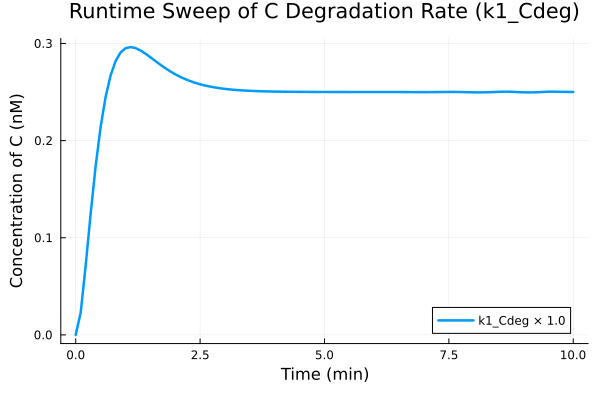

In [8]:
# Exercise 2 starter code — edit to sweep k1_Cdeg across [0.25, 1.0, 3.0] and plot species C!
idx_Cdeg = findfirst(x -> x == "k1_Cdeg", parameterNameList)
idx_C    = findfirst(x -> x == "C", syms)
println("k1_Cdeg is parameter #", idx_Cdeg, "; species C is variable #", idx_C)

# Currently only simulates baseline (1.0x) — extend multipliers to [0.25, 1.0, 3.0]!
multipliers = [1.0]

plt = plot(
    xlabel = "Time (min)",
    ylabel = "Concentration of C (nM)",
    title  = "Runtime Sweep of C Degradation Rate (k1_Cdeg)",
)

for mult in multipliers
    p_test = copy(paramVals)
    p_test[idx_Cdeg] = p_test[idx_Cdeg] * mult
    sol_test = solve(ODEProblem(ODEFunction(toy_param), [1.0, 0.0, 0.0], (0.0, 10.0), p_test), saveat=0.1)
    plot!(plt, sol_test.t, sol_test[idx_C, :], label="k1_Cdeg × $(mult)", lw=2.5)
end

plt

```{admonition} Hint
:class: dropdown tip

You only need to update one line: change `multipliers = [1.0]` to `multipliers = [0.25, 1.0, 3.0]`!
Watch how making `C` degrade 4× slower (`0.25×`) lets `C` accumulate much higher, while 3× faster degradation (`3.0×`) keeps `C` low!
```

````{admonition} Reveal Solution
:class: dropdown note

```julia
idx_Cdeg = findfirst(x -> x == "k1_Cdeg", parameterNameList)
idx_C    = findfirst(x -> x == "C", syms)

multipliers = [0.25, 1.0, 3.0]

plt = plot(
    xlabel = "Time (min)",
    ylabel = "Concentration of C (nM)",
    title  = "Runtime Sweep of C Degradation Rate (k1_Cdeg)",
)

for mult in multipliers
    p_test = copy(paramVals)
    p_test[idx_Cdeg] = p_test[idx_Cdeg] * mult
    sol_test = solve(ODEProblem(ODEFunction(toy_param), [1.0, 0.0, 0.0], (0.0, 10.0), p_test), saveat=0.1)
    plot!(plt, sol_test.t, sol_test[idx_C, :], label="k1_Cdeg × $(mult)", lw=2.5)
end

plt
```
````

Awesome! Now that you know how `CSV2Julia` works and how **`param` mode** lets you pass a `paramVals` vector into `ODEProblem`, you're ready for the coolest feature of `param` mode: **putting time-dependent input curves inside `paramVals`**!

Head to **[2. Creating Time-Dependent Input Curves](./02-time-dependent-inputs.ipynb)**!